In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-212.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-211.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/X_train_pre.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/camembert_training_history.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/images_analysis.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-213.keras
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/history_212.pkl
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/lang.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/history_211.pkl
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/translation.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train_clean.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/label_mapping.json
/kaggle/input/datasets/tarikouhsine/

KeyboardInterrupt: 

# CELLULE 1 — Installation & Imports

In [3]:
!pip install tf-keras-vis -q

import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import f1_score
import keras.saving
from keras.models import load_model

from tf_keras_vis.activation_maximization import ActivationMaximization

# ── Chemins Kaggle ───────────────────────────────────────────────────────────
INPUT_DIR  = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
WORK_DIR   = Path('/kaggle/working')
IMAGE_DIR  = INPUT_DIR / 'images' / 'images' / 'image_train'

print(f"TensorFlow : {tf.__version__}")
print(f"GPU dispo  : {tf.config.list_physical_devices('GPU')}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 1.9 MB/s eta 0:00:00


2026-05-24 22:44:29.945695: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779662670.139180      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779662670.206349      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779662670.677163      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779662670.677205      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779662670.677208      57 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU dispo  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# CELLULE 2 — Métrique & Mapping des classes

In [4]:
NUM_CLASSES = 27

# Métrique compatible avec le chargement des modèles sauvegardés
@keras.saving.register_keras_serializable(name='WeightedF1Score')
class WeightedF1Score(tf.keras.metrics.Metric):
    def __init__(self, num_classes=NUM_CLASSES, name='w_f1_score', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.tp      = self.add_weight(shape=(num_classes,), initializer='zeros', name='tp')
        self.fp      = self.add_weight(shape=(num_classes,), initializer='zeros', name='fp')
        self.fn      = self.add_weight(shape=(num_classes,), initializer='zeros', name='fn')
        self.support = self.add_weight(shape=(num_classes,), initializer='zeros', name='support')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true_cls = tf.argmax(y_true, axis=1)
        y_pred_cls = tf.argmax(y_pred, axis=1)
        y_true_oh  = tf.one_hot(y_true_cls, self.num_classes)
        y_pred_oh  = tf.one_hot(y_pred_cls, self.num_classes)
        self.tp.assign_add(tf.reduce_sum(y_true_oh * y_pred_oh, axis=0))
        self.fp.assign_add(tf.reduce_sum((1 - y_true_oh) * y_pred_oh, axis=0))
        self.fn.assign_add(tf.reduce_sum(y_true_oh * (1 - y_pred_oh), axis=0))
        self.support.assign_add(tf.reduce_sum(y_true_oh, axis=0))

    def result(self):
        eps       = tf.keras.backend.epsilon()
        precision = self.tp / (self.tp + self.fp + eps)
        recall    = self.tp / (self.tp + self.fn + eps)
        f1        = 2 * precision * recall / (precision + recall + eps)
        weights   = self.support / (tf.reduce_sum(self.support) + eps)
        return tf.reduce_sum(f1 * weights)

    def reset_state(self):
        zeros = tf.zeros(self.num_classes)
        self.tp.assign(zeros); self.fp.assign(zeros)
        self.fn.assign(zeros); self.support.assign(zeros)

    def get_config(self):
        config = super().get_config()
        config.update({"num_classes": self.num_classes})
        return config

CODE2LABEL = {
    10:'Livre occasion', 40:'Jeu vidéo, accessoire tech',
    50:'Accessoire Console', 60:'Console de jeu',
    1140:'Figurine', 1160:'Carte Collection',
    1180:'Jeu Plateau', 1280:'Jouet enfant, déguisement',
    1281:'Jeu société', 1300:'Jouet tech',
    1301:'Jeu intérieur, chaussettes', 1302:'Jeu extérieur, vêtement',
    1320:'Bébé', 1560:'Mobilier intérieur',
    1920:'Chambre', 1940:'Cuisine',
    2060:'Décoration intérieure', 2220:'Animal',
    2280:'Revues, journaux', 2403:'Magazines, livres, BDs',
    2462:'Jeu occasion', 2522:'Bureautique, papeterie',
    2582:'Mobilier extérieur', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

print("✅ Métrique et mapping prêts")

✅ Métrique et mapping prêts


# CELLULE 3 — Chargement des données et du modèle

In [5]:
df_test = pd.read_csv(INPUT_DIR / 'df_test.csv', index_col=0)

classes_keras = list(np.sort(
    np.array(df_test['prdtypecode'].unique(), dtype="str")
))
print(f"Classes ({len(classes_keras)}) : {classes_keras}")

# ── Chargement du modèle ─────────────────────────────────────────────────────
# Change le chemin selon le modèle que tu veux visualiser :
#   VGG16   → WORK_DIR / 'vgg16_best.pth'          (PyTorch, pas compatible ici)
#   LeNet   → WORK_DIR / 'modeling-lenet' / 'model-113.keras'
#   ResNet  → WORK_DIR / 'modeling-resnet' / 'model-213.keras'
#
# Note : ce notebook fonctionne uniquement avec les modèles Keras (.keras)

MODEL_PATH = INPUT_DIR / 'model-213.keras'

print(f"Chargement du modèle : {MODEL_PATH}")
model = load_model(
    MODEL_PATH,
    custom_objects={'WeightedF1Score': WeightedF1Score}
)
print(f"✅ Modèle chargé")
print(f"   Input shape  : {model.input_shape}")
print(f"   Output shape : {model.output_shape}")
model.summary()

Classes (27) : [np.str_('10'), np.str_('1140'), np.str_('1160'), np.str_('1180'), np.str_('1280'), np.str_('1281'), np.str_('1300'), np.str_('1301'), np.str_('1302'), np.str_('1320'), np.str_('1560'), np.str_('1920'), np.str_('1940'), np.str_('2060'), np.str_('2220'), np.str_('2280'), np.str_('2403'), np.str_('2462'), np.str_('2522'), np.str_('2582'), np.str_('2583'), np.str_('2585'), np.str_('2705'), np.str_('2905'), np.str_('40'), np.str_('50'), np.str_('60')]
Chargement du modèle : /kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/model-213.keras


I0000 00:00:1779662710.042072      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779662710.048068      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ Modèle chargé
   Input shape  : (None, 224, 224, 3)
   Output shape : (None, 27)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 98,487,251 (375.70 MB)

 Trainable params: 18,736,667 (71.47 MB)

 Non-trainable params: 42,277,248 (161.27 MB)

 Optimizer params: 37,473,336 (142.95 MB)

# CELLULE 4 — Configuration Activation Maximization

In [6]:
def model_modifier(m):
    """Remplace softmax par linéaire pour une meilleure visualisation."""
    m.layers[-1].activation = tf.keras.activations.linear

# Initialisation
visualize_activation = ActivationMaximization(model, model_modifier)
print("✅ ActivationMaximization prêt")
print(f"   Modèle     : {MODEL_PATH.name}")
print(f"   Classes    : {len(classes_keras)}")
print(f"   Input size : {model.input_shape[1:]}")

✅ ActivationMaximization prêt
   Modèle     : model-213.keras
   Classes    : 27
   Input size : (224, 224, 3)


# CELLULE 5 — Visualisation Test 1 : activation par classe individuelle

In [7]:
# Loss : maximise l'activation de la i-ème classe pour la i-ème image
def loss_v1(output):
    return tuple([output[i, i] for i in range(len(classes_keras))])

# Seed aléatoire — une image par classe
seed_input = tf.random.uniform(
    (len(classes_keras), 224, 224, 3), minval=0, maxval=255
)

print(f"⏳ Génération des activations (512 steps × {len(classes_keras)} classes)...")
print("   Durée estimée : 5-10 min avec GPU T4")

activations_v1 = visualize_activation(
    loss_v1,
    seed_input=seed_input,
    steps=512,
    input_range=(30, 150)
)
print("✅ Activations générées")

⏳ Génération des activations (512 steps × 27 classes)...
   Durée estimée : 5-10 min avec GPU T4


I0000 00:00:1779662764.309735      57 cuda_dnn.cc:529] Loaded cuDNN version 91002


✅ Activations générées


# CELLULE 6 — Affichage Test 1

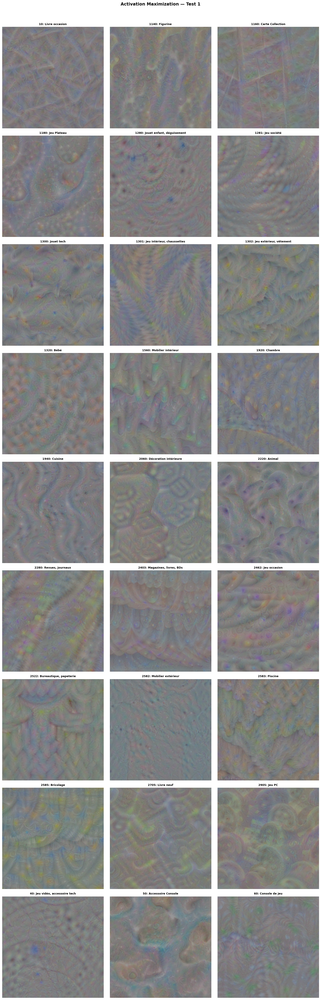

✅ Figure sauvegardée dans /kaggle/working/


In [8]:
def plot_activations(activations, title="Activation Maximization"):
    images = [act.numpy().astype(np.uint8) for act in activations]
    n_cols = 3
    n_rows = (len(images) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
    axes = axes.flatten()

    for i, (img, ax) in enumerate(zip(images, axes)):
        ax.imshow(img)
        classe = classes_keras[i]
        label  = CODE2LABEL.get(int(classe), classe)
        ax.set_title(f"{classe}: {label}", fontsize=9, fontweight='bold')
        ax.axis('off')

    # Masquer les axes vides si nombre impair
    for j in range(len(images), len(axes)):
        axes[j].axis('off')

    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(WORK_DIR / f'{title.replace(" ", "_").lower()}.png',
                dpi=120, bbox_inches='tight')
    plt.show()
    print(f"✅ Figure sauvegardée dans /kaggle/working/")

plot_activations(activations_v1, title="Activation Maximization — Test 1")

# CELLULE 7 — Visualisation Test 2 : activation maximale par classe

⏳ Génération activations Test 2...
✅ Activations générées


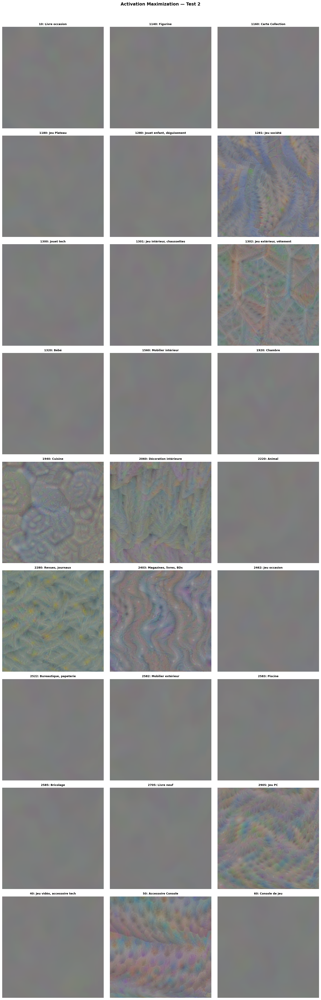

✅ Figure sauvegardée dans /kaggle/working/


In [9]:
# Loss : maximise le score max de chaque classe sur toutes les images du batch
def loss_v2(output):
    return tuple([tf.reduce_max(output[:, i]) for i in range(len(classes_keras))])

# Nouvelle seed aléatoire
seed_input = tf.random.uniform(
    (len(classes_keras), 224, 224, 3), minval=0, maxval=255
)

print("⏳ Génération activations Test 2...")
activations_v2 = visualize_activation(
    loss_v2,
    seed_input=seed_input,
    steps=512,
    input_range=(30, 150)
)
print("✅ Activations générées")

plot_activations(activations_v2, title="Activation Maximization — Test 2")

# CELLULE 8 — Vérification : le modèle prédit bien la classe visualisée

In [10]:
# Vérifie que l'image maximisant la classe i est bien prédite comme classe i
images_v1 = [act.numpy().astype(np.uint8) for act in activations_v1]

print("Vérification des prédictions sur les images générées :\n")
print(f"{'Classe':>6}  {'Label':<30}  {'Prédite':>8}  {'Proba':>6}  {'Correct':>7}")
print("-" * 65)

correct = 0
for i, img in enumerate(images_v1):
    # Normalisation comme pendant l'entraînement
    img_norm  = img.astype(np.float32) / 255.0
    img_batch = np.expand_dims(img_norm, axis=0)

    preds     = model.predict(img_batch, verbose=0)[0]
    pred_idx  = np.argmax(preds)
    pred_cls  = classes_keras[pred_idx]
    proba     = preds[pred_idx]
    vrai_cls  = classes_keras[i]
    label     = CODE2LABEL.get(int(vrai_cls), vrai_cls)
    ok        = "✅" if pred_cls == vrai_cls else "❌"
    if pred_cls == vrai_cls:
        correct += 1

    print(f"{vrai_cls:>6}  {label:<30}  {pred_cls:>8}  {proba:>5.1%}  {ok:>7}")

print(f"\n→ {correct}/{len(classes_keras)} classes correctement activées ({correct/len(classes_keras)*100:.0f}%)")

Vérification des prédictions sur les images générées :

Classe  Label                            Prédite   Proba  Correct
-----------------------------------------------------------------


I0000 00:00:1779665070.020123     139 service.cc:152] XLA service 0x78704c002d00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779665070.020179     139 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1779665070.020185     139 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1779665075.598994     139 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    10  Livre occasion                      2583  15.5%        ❌
  1140  Figurine                            2583  16.2%        ❌
  1160  Carte Collection                    2583  16.4%        ❌
  1180  Jeu Plateau                         2583  15.6%        ❌
  1280  Jouet enfant, déguisement           2583  15.7%        ❌
  1281  Jeu société                         2583  16.2%        ❌
  1300  Jouet tech                          2583  14.6%        ❌
  1301  Jeu intérieur, chaussettes          2583  16.2%        ❌
  1302  Jeu extérieur, vêtement             2583  14.6%        ❌
  1320  Bébé                                2583  15.0%        ❌
  1560  Mobilier intérieur                  2583  14.8%        ❌
  1920  Chambre                             2583  16.0%        ❌
  1940  Cuisine                             2583  13.8%        ❌
  2060  Décoration intérieure               2583  15.7%        ❌
  2220  Animal                              2583  14.1%        ❌
  2280  Revues, journaux 

# CELLULE 9 — Comparaison côte à côte Test 1 vs Test 2

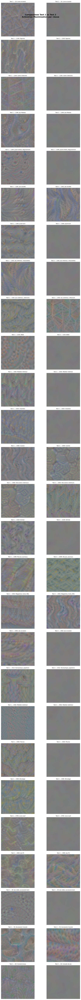

In [11]:
images_v1 = [act.numpy().astype(np.uint8) for act in activations_v1]
images_v2 = [act.numpy().astype(np.uint8) for act in activations_v2]

n = len(classes_keras)
fig, axes = plt.subplots(n, 2, figsize=(10, n * 3.5))

for i in range(n):
    classe = classes_keras[i]
    label  = CODE2LABEL.get(int(classe), classe)

    axes[i, 0].imshow(images_v1[i])
    axes[i, 0].set_title(f"Test 1 — {classe}: {label}", fontsize=8)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(images_v2[i])
    axes[i, 1].set_title(f"Test 2 — {classe}: {label}", fontsize=8)
    axes[i, 1].axis('off')

plt.suptitle("Comparaison Test 1 vs Test 2\nActivation Maximization par classe",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(WORK_DIR / 'activation_maximization_comparaison.png',
            dpi=100, bbox_inches='tight')
plt.show()

### 